### Лабораторная работа №4: Байесовская сеть

In [4]:
import os, itertools, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.stats import chi2_contingency
%matplotlib inline

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from pgmpy.estimators import HillClimbSearch
from pgmpy.estimators.CITests import chi_square

try:
    from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE
    from pgmpy.structure_score import BIC, BDeu
    NEW_API = True
except ImportError:
    from pgmpy.estimators import BayesianEstimator, MaximumLikelihoodEstimator, BIC, BDeu
    NEW_API = False

import pgmpy
print("pgmpy", pgmpy.__version__, "| новый API:", NEW_API)
sns.set_theme(style="darkgrid")

pgmpy 1.1.2 | новый API: True


## 1. Выбор данных

**Датасет:** [Student Performance](https://www.kaggle.com/datasets/whenamancodes/student-performance), таблица `Maths.csv` (исходник — UCI *Student Performance*, школьники двух португальских школ, предмет «математика»).

**Один объект** — один школьник. В таблице 395 объектов и 33 признака (демография, семья, образ жизни, школьные показатели, оценки).

**Почему не берём все 33 признака.** Размер таблицы условных вероятностей (CPT) растёт экспоненциально с числом родителей и числом состояний (слайд «Дискретизация и размер CPT»). Уже узел с тремя родителями по 4–5 состояний — это 60–125 конфигураций на 395 наблюдений, то есть по 3–6 объектов на строку CPT. Поэтому выбираем **6 переменных**, между которыми можно объяснить зависимости без специальных знаний о предметной области:

| Переменная | Что означает (по документации датасета) | Тип | Роль в модели |
|---|---|---|---|
| `studytime` | недельное время учёбы вне школы: 1 — <2 ч, 2 — 2–5 ч, 3 — 5–10 ч, 4 — >10 ч | порядковая, 4 уровня | привычка/усилия студента |
| `failures` | число прошлых «провалов» по предметам (значения 0–3) | порядковая | история успеваемости (до текущего года) |
| `absences` | число школьных пропусков (агрегированный счётчик; считаем его накопленным за учебный год) | счётчик 0–75 | поведение |
| `G1` | оценка за первый период, шкала 0–20 | порядковая | промежуточный результат |
| `G2` | оценка за второй период, 0–20 | порядковая | промежуточный результат |
| `G3` | итоговая оценка, 0–20 | порядковая | **целевая переменная** |

**Какие зависимости можно ожидать.**
- Оценки идут во времени друг за другом: `G1 → G2 → G3`, каждая сильно зависит от предыдущей (знания накапливаются).
- Прошлые неудачи (`failures`) предшествуют всем текущим оценкам и могут их ухудшать.
- Усилия (`studytime`) могут повышать оценки; пропуски (`absences`) — понижать итоговую.
- Прошлые неудачи могут быть связаны с поведением (пропусками).

Выбор признаков — ваша идея из задания; я её проверил на данных (см. разделы 2 и 4) и оставил без замен: все шесть переменных содержательны, а их состояний хватает для сети на 395 наблюдениях.

In [5]:
# Положите Maths.csv (Kaggle) рядом с ноутбуком. Если файла нет — берём ту же таблицу из исходного репозитория UCI-зеркала.
LOCAL = "Maths.csv"
URL = "https://raw.githubusercontent.com/arunk13/MSDA-Assignments/master/IS607Fall2015/Assignment3/student-mat.csv"
src = LOCAL if os.path.exists(LOCAL) else URL

raw = pd.read_csv(src, sep=";")
if raw.shape[1] == 1:           # на случай, если разделитель запятая
    raw = pd.read_csv(src, sep=",")

print("Источник:", src)
print("Размер таблицы:", raw.shape)
print("Пропусков во всей таблице:", int(raw.isna().sum().sum()))
display(raw[["studytime", "failures", "absences", "G1", "G2", "G3"]].describe().T)
raw.head()

Источник: https://raw.githubusercontent.com/arunk13/MSDA-Assignments/master/IS607Fall2015/Assignment3/student-mat.csv
Размер таблицы: (395, 33)
Пропусков во всей таблице: 0


,count,mean,std,min,25%,50%,75%,max
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
absences,395.0,5.708861,8.003096,0.0,0.0,4.0,8.0,75.0
G1,395.0,10.908861,3.319195,3.0,8.0,11.0,13.0,19.0
G2,395.0,10.713924,3.761505,0.0,9.0,11.0,13.0,19.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Подготовка данных

**Пропущенные значения.** В таблице нет ни одного пропуска (проверка выше), поэтому заполнять/удалять ничего не нужно.

**Дискретизация.** Байесовская сеть из `pgmpy` работает с дискретными переменными, поэтому непрерывные/счётные признаки переводим в категории. Чем больше состояний, тем больше строк в CPT (слайд «Дискретизация и размер CPT»), поэтому категорий мало — 3–4:

| Переменная | Преобразование | Обоснование |
|---|---|---|
| `studytime` | без изменений (1, 2, 3, 4) | уже 4 категории; значение 4 редкое (27 объектов), но смысл у него самостоятельный — «>10 часов в неделю». Редкость компенсируем сглаживанием (раздел 5) |
| `failures` | 0, 1, **2+** (значения 2 и 3 объединены) | значения 2 и 3 встречаются 17 и 16 раз — по отдельности слишком редко; вместе 33 объекта |
| `absences` | **0–4, 5–10, >10** | распределение с тяжёлым хвостом (максимум 75, медиана 4). Границы взяты у вас: ≈62% / 22% / 17% — три сопоставимых по размеру группы, в самой малой 66 объектов |
| `G1`, `G2`, `G3` | **Low** (0–9), **Medium** (10–13), **High** (14–20) | 10 — проходной балл в португальской системе (0–20), поэтому граница 9/10 имеет смысл «не сдал / сдал»; 14+ — «хорошо». Классы получаются почти сбалансированными (для `G3`: 33% / 42% / 25%; для `G1`, `G2` — 36–37% / 40% / 23–24%) |

**Что проверяем:**
- *Редкие категории:* самые малочисленные — `failures=2+` (33), `studytime=4` (27), `absences>10` (66). Все ≥ 27 объектов, но в комбинациях родителей их будет мало — смотрим это в разделе 4.
- *Количество состояний:* 4, 3, 3, 3, 3, 3 — сеть остаётся компактной.
- *Подозрительные значения:* 38 студентов имеют `G3 = 0` (и у 13 студентов `G2 = 0`) — это, по-видимому, студенты, не явившиеся на итоговую оценку/бросившие курс. **У всех 38 `absences = 0`** — это артефакт данных (скорее всего, пропуски не фиксировались у выбывших), и он повлияет на результаты: мы его не удаляем, а аккуратно разберём в разделе 5.

переменная,studytime,failures,absences,G1,G2,G3
состояние,,,,,,
0,,312.0,,,,
0-4,,,244.0,,,
1,105.0,50.0,,,,
2,198.0,,,,,
2+,,33.0,,,,
3,65.0,,,,,
4,27.0,,,,,
5-10,,,85.0,,,
>10,,,66.0,,,


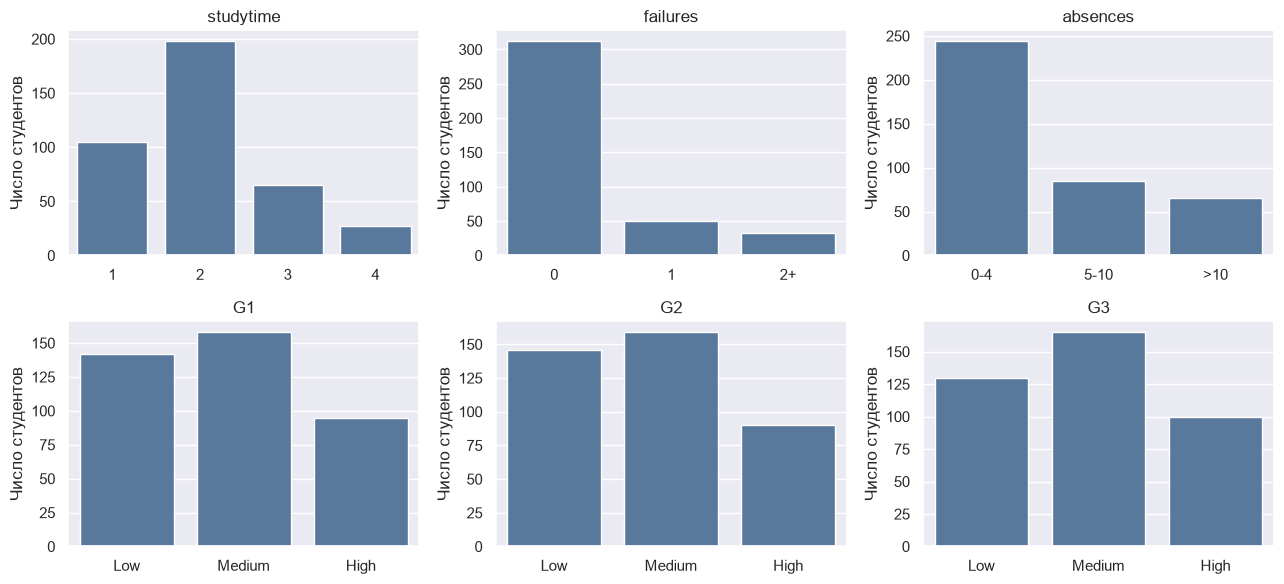

G1 == 0: 0 | G2 == 0: 13 | G3 == 0: 38
Абсентеизм у студентов с G3 == 0: среднее = 0.0 , максимум = 0


In [6]:
for c in ["studytime", "failures", "absences", "G1", "G2", "G3"]:
    raw[c] = pd.to_numeric(raw[c])          # G1/G2 в исходном файле могут быть записаны строками

GRADE = ["Low", "Medium", "High"]
STATES = {
    "studytime": ["1", "2", "3", "4"],
    "failures":  ["0", "1", "2+"],
    "absences":  ["0-4", "5-10", ">10"],
    "G1": GRADE, "G2": GRADE, "G3": GRADE,
}
NODES = list(STATES)

def grade_level(s):
    return pd.cut(s, bins=[-1, 9, 13, 20], labels=GRADE).astype(str)

bn_df = pd.DataFrame({
    "studytime": raw["studytime"].astype(str),
    "failures":  raw["failures"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"}),
    "absences":  pd.cut(raw["absences"], bins=[-1, 4, 10, np.inf], labels=STATES["absences"]).astype(str),
    "G1": grade_level(raw["G1"]),
    "G2": grade_level(raw["G2"]),
    "G3": grade_level(raw["G3"]),
})

# Таблица состояний: число объектов и доля
rows = []
for v in NODES:
    vc = bn_df[v].value_counts().reindex(STATES[v])
    for s, n in vc.items():
        rows.append((v, s, n, n / len(bn_df)))
state_table = pd.DataFrame(rows, columns=["переменная", "состояние", "N", "доля"])
display(state_table.pivot(index="состояние", columns="переменная", values="N")[NODES].fillna(""))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, v in zip(axes.ravel(), NODES):
    sns.countplot(x=bn_df[v], order=STATES[v], ax=ax, color="#4c78a8")
    ax.set_title(v); ax.set_xlabel(""); ax.set_ylabel("Число студентов")
plt.tight_layout(); plt.show()

# Подозрительные нули в оценках и пропуски
print("G1 == 0:", int((raw.G1 == 0).sum()), "| G2 == 0:", int((raw.G2 == 0).sum()), "| G3 == 0:", int((raw.G3 == 0).sum()))
print("Абсентеизм у студентов с G3 == 0: среднее =", raw.loc[raw.G3 == 0, "absences"].mean(), ", максимум =", raw.loc[raw.G3 == 0, "absences"].max())

## 3. Вопросы к модели

Сформулируем вопросы **до** построения сети:

1. **(Предсказание)** Как изменится распределение итоговой оценки `G3`, если известно, что у студента были прошлые неудачи (`failures = 2+`)?
2. **(Вклад пропусков и «чистый» эффект)** Как меняется `G3` при большом числе пропусков (`absences > 10`) и насколько это объясняется тем, что такие студенты чаще имели прошлые неудачи?
3. **(Диагностика, «обратный» вывод)** Если итоговая оценка низкая (`G3 = Low`) или высокая (`High`), что можно сказать о прошлых неудачах и времени учёбы студента?
4. **(Роль промежуточных оценок)** Что ещё имеет значение для `G3`, если уже известны `G2` и `absences`? Меняется ли ответ при добавлении `G1`, `failures`, `studytime`?
5. **(Структура)** Что изменится в ответах, если убрать одно из рёбер, и можно ли по данным определить направление рёбер?

## 4. Построение графа

### 4.1. Что говорят данные о зависимостях

Рёбра мы выбираем **по смыслу**, а не по корреляции. Но данные полезно использовать как проверку гипотез: хи-квадрат тест на (условную) независимость показывает, где предполагаемая независимость нарушается. Это ориентир, а не «приговор»: тестов много, N = 395, для некоторых условных наборов в ячейках по несколько наблюдений.

In [7]:
def ci_p(x, y, z=()):
    """p-value хи-квадрат теста условной независимости X _||_ Y | Z"""
    return chi_square(x, y, list(z), bn_df, boolean=False, significance_level=0.05)[1]

tests = [
    ("failures",  "G1", [],                      "Связаны ли прошлые неудачи и оценка первого периода?"),
    ("studytime", "G1", [],                      "Связано ли время учёбы с оценкой первого периода?"),
    ("absences",  "G1", [],                      "Связаны ли пропуски с оценкой первого периода?"),
    ("failures",  "absences", [],                "Связаны ли прошлые неудачи и пропуски?"),
    ("G1",        "G3", ["G2"],                  "Цепочка: G1 не даёт новой информации о G3, если известна G2?"),
    ("failures",  "G2", ["G1"],                  "Прошлые неудачи не влияют на G2, если известна G1?"),
    ("studytime", "G2", ["G1"],                  "Время учёбы не влияет на G2, если известна G1?"),
    ("failures",  "G3", ["G2", "absences"],      "Неудачи не влияют на G3 при известных G2 и пропусках?"),
    ("studytime", "G3", ["G2", "absences"],      "Время учёбы не влияет на G3 при известных G2 и пропусках?"),
    ("absences",  "G3", ["G2"],                  "Пропуски влияют на G3 сверх G2?"),
]
ci_table = pd.DataFrame(
    [(f"{a} ⫫ {b}" + (f" | {', '.join(z)}" if z else ""), round(ci_p(a, b, z), 4), q) for a, b, z, q in tests],
    columns=["проверяемая независимость", "p-value", "что проверяем"])
ci_table["вывод (α=0.05)"] = np.where(ci_table["p-value"] < 0.05, "зависимость есть", "независимость не отвергается")
ci_table

,проверяемая независимость,p-value,что проверяем,вывод (α=0.05)
0,failures ⫫ G1,0.0000,Связаны ли прошлые неудачи и оценка первого пе...,зависимость есть
1,studytime ⫫ G1,0.0305,Связано ли время учёбы с оценкой первого периода?,зависимость есть
2,absences ⫫ G1,0.6363,Связаны ли пропуски с оценкой первого периода?,независимость не отвергается
3,failures ⫫ absences,0.0001,Связаны ли прошлые неудачи и пропуски?,зависимость есть
4,G1 ⫫ G3 | G2,0.0312,"Цепочка: G1 не даёт новой информации о G3, есл...",зависимость есть
5,failures ⫫ G2 | G1,0.0008,"Прошлые неудачи не влияют на G2, если известна...",зависимость есть
6,studytime ⫫ G2 | G1,0.0137,"Время учёбы не влияет на G2, если известна G1?",зависимость есть
7,"failures ⫫ G3 | G2, absences",0.8459,Неудачи не влияют на G3 при известных G2 и про...,независимость не отвергается
8,"studytime ⫫ G3 | G2, absences",0.7512,Время учёбы не влияет на G3 при известных G2 и...,независимость не отвергается
9,absences ⫫ G3 | G2,0.0547,Пропуски влияют на G3 сверх G2?,независимость не отвергается


**Что показали тесты.**
- Сильные зависимости: `failures–G1` (p < 10⁻⁹), `failures–absences` (p ≈ 10⁻⁴); `studytime–G1` слабая (p ≈ 0.03); `absences–G1` нет (p ≈ 0.64) — пропуски связаны не с первым периодом, а с итогом.
- После `G2` и `absences` ни `failures`, ни `studytime` для `G3` информации не добавляют (p = 0.85 и 0.75) — значит, прямых рёбер в `G3` от них не нужно.
- **Неожиданность:** `failures ⫫ G2 | G1` отвергается (p ≈ 0.0008) — прошлые неудачи говорят о `G2` что-то сверх `G1`. Причина — грубая дискретизация: группа `Medium` (10–13) скрывает разницу между 10 и 13, и неудачи несут информацию о том, где внутри группы находится студент. Поэтому в граф добавляем ребро `failures → G2`.
- `absences ⫫ G3 | G2` не отвергается на уровне 5% (p ≈ 0.055) — ребро `absences → G3` пограничное. Оставляем его, так как оно содержательное и нужно для вопросов 2 и 5; проверим его необходимость в разделе 8.
- `G1 ⫫ G3 | G2` отвергается слабо (p ≈ 0.03) — ребро `G1 → G3` не добавляем (эффект малый, и ребро утроило бы число родителей `G3`).
- `studytime ⫫ G2 | G1` тоже отвергается (p ≈ 0.014); ребро `studytime → G2` не добавляем из-за размера CPT: у `G2` было бы 36 конфигураций родителей на 395 объектов.

### 4.2. Рёбра и их обоснование

| Ребро | Почему зависимость | Почему такое направление |
|---|---|---|
| `studytime → G1` | больше учебного времени — выше оценка (слабый эффект, p ≈ 0.03) | время учёбы — привычка студента, задаётся до и в течение периода; оценка не может «вернуться» и изменить уже прожитое время |
| `failures → G1` | студенты с прошлыми неудачами хуже учатся (сильная связь) | `failures` относится к **прошлому** — текущие оценки на прошлое повлиять не могут |
| `failures → G2` | устойчивая слабая подготовка влияет на успеваемость и во втором периоде сверх `G1` (т.к. `G1` грубо дискретизирована) | то же: прошлое → настоящее |
| `failures → absences` | студенты с неудачами в прошлом чаще пропускают занятия (потеря мотивации, «отстающие» чаще прогуливают) | временной порядок. **Направление по данным определить нельзя** (см. раздел 8 — марковская эквивалентность): выбрано по смыслу |
| `absences → G3` | пропуски копятся и сказываются на итоге | предполагаем, что признак накопительный (агрегат за год), поэтому связываем его с итоговой оценкой, а не с `G1` (`absences ⫫ G1`, p ≈ 0.64) |
| `G1 → G2 → G3` | знания накапливаются, каждая оценка определяется предыдущей | хронологический порядок периодов |

**Не добавлены:** `studytime → G3`, `failures → G3` (тесты показывают независимость при известных `G2`, `absences`), `absences → G1` (p ≈ 0.64), `studytime ↔ failures` (связь на границе значимости, p ≈ 0.06 — а ребро «только по корреляции» добавлять не стоит; влияние этого решения проверим в разделе 8).

Граф ориентирован и ацикличен (проверяется в коде).

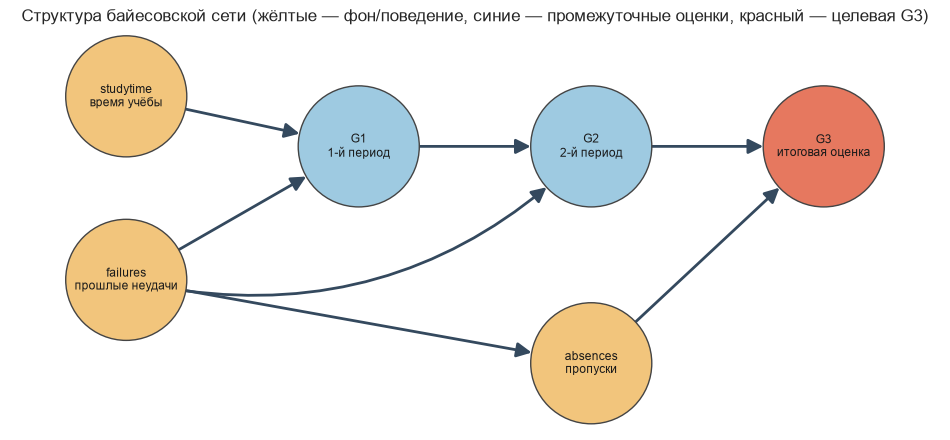

In [8]:
EDGES = [
    ("studytime", "G1"),
    ("failures",  "G1"),
    ("failures",  "G2"),
    ("failures",  "absences"),
    ("absences",  "G3"),
    ("G1",        "G2"),
    ("G2",        "G3"),
]
dag = nx.DiGraph(EDGES)
assert nx.is_directed_acyclic_graph(dag)

pos = {"studytime": (0, 1.3), "failures": (0, -0.9), "G1": (2.6, 0.7), "G2": (5.2, 0.7),
       "G3": (7.8, 0.7), "absences": (5.2, -1.9)}
labels = {"studytime": "studytime\nвремя учёбы", "failures": "failures\nпрошлые неудачи",
          "absences": "absences\nпропуски", "G1": "G1\n1-й период", "G2": "G2\n2-й период", "G3": "G3\nитоговая оценка"}
colors = {"studytime": "#f2c57c", "failures": "#f2c57c", "absences": "#f2c57c",
          "G1": "#9ecae1", "G2": "#9ecae1", "G3": "#e6785f"}

def draw_dag(graph, title, ax, highlight=None, dashed=()):
    nx.draw_networkx_nodes(graph, pos, node_color=[colors[n] for n in graph.nodes], node_size=7600,
                           edgecolors="#444", ax=ax)
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=8.5, ax=ax)
    for u, v in graph.edges:
        rad = 0.28 if (u, v) == ("failures", "G2") else 0.0
        nx.draw_networkx_edges(graph, pos, edgelist=[(u, v)], node_size=7600, arrowsize=22, width=2,
                               edge_color="#c0392b" if (u, v) in dashed else "#34495e",
                               style="dashed" if (u, v) in dashed else "solid",
                               connectionstyle=f"arc3,rad={rad}", ax=ax)
    ax.set_title(title); ax.set_xlim(-1.3, 9.1); ax.set_ylim(-2.7, 2.1); ax.axis("off")

fig, ax = plt.subplots(figsize=(12, 5.2))
draw_dag(dag, "Структура байесовской сети (жёлтые — фон/поведение, синие — промежуточные оценки, красный — целевая G3)", ax)
plt.show()

**Сравнение.**
- Совпадает цепочка оценок `G1 – G2 – G3` (направление развёрнуто: `G3 → G2 → G1` — но цепочка из трёх узлов без коллайдеров марковски эквивалентна нашей; данные не отличают «время вперёд» от «время назад», см. раздел 8) и связь `failures – absences` (в варианте BDeu).
- И BIC, и BDeu связывают `failures` именно с `G2`, а не с `G1` — это подтверждает наше ребро `failures → G2`.
- BIC даёт очень разреженный граф (3 ребра): он сильно штрафует число параметров при N = 395 и отбрасывает `studytime` и `absences` совсем. BDeu оставляет больше связей. Для вопросов лабораторной нам нужны именно `studytime` и `absences`, поэтому мы опираемся на содержательные гипотезы, а не на лучший score.

### 4.3. Размер CPT и достаточность наблюдений

In [9]:
def fit_bn(edges, ess=5, mle=False, data=None):
    """Строим сеть по списку рёбер и оцениваем CPT. По умолчанию — байесовская оценка со сглаживанием BDeu."""
    data = bn_df if data is None else data
    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(NODES)
    if NEW_API:
        est = DiscreteMLE() if mle else DiscreteBayesianEstimator(state_names=STATES, prior_type="BDeu", equivalent_sample_size=ess)
        model.fit(data, estimator=est)
    else:
        if mle:
            model.fit(data, estimator=MaximumLikelihoodEstimator)
        else:
            model.fit(data, estimator=BayesianEstimator, prior_type="BDeu", equivalent_sample_size=ess, state_names=STATES)
    assert model.check_model()
    return model

def ask(model, var, evidence=None):
    """Точный вывод (Variable Elimination): распределение var при заданном evidence."""
    r = VariableElimination(model).query([var], evidence=evidence or {}, show_progress=False)
    return pd.Series(np.asarray(r.values, dtype=float), index=r.state_names[var]).reindex(STATES[var])

def mask(evidence, data=None):
    data = bn_df if data is None else data
    m = pd.Series(True, index=data.index)
    for k, v in (evidence or {}).items():
        m &= data[k] == v
    return m

def empirical(var, evidence=None):
    """Доля по данным среди объектов, удовлетворяющих evidence, и их число."""
    m = mask(evidence)
    return bn_df.loc[m, var].value_counts(normalize=True).reindex(STATES[var]).fillna(0.0), int(m.sum())

model = fit_bn(EDGES, ess=5)
print("check_model:", model.check_model())
print("Рёбра:", sorted(model.edges()))
print("Марковское одеяло G3:", sorted(model.get_markov_blanket("G3")))
for n in NODES:
    pa = model.get_parents(n)
    n_cfg = int(np.prod([len(STATES[p]) for p in pa])) if pa else 1
    free = n_cfg * (len(STATES[n]) - 1)
    print(f"{n:10s} родители={pa!s:24s} конфигураций родителей={n_cfg:3d}, свободных параметров={free}")

check_model: True
Рёбра: [('G1', 'G2'), ('G2', 'G3'), ('absences', 'G3'), ('failures', 'G1'), ('failures', 'G2'), ('failures', 'absences'), ('studytime', 'G1')]
Марковское одеяло G3: ['G2', 'absences']
studytime  родители=[]                       конфигураций родителей=  1, свободных параметров=3
failures   родители=[]                       конфигураций родителей=  1, свободных параметров=2
absences   родители=['failures']             конфигураций родителей=  3, свободных параметров=6
G1         родители=['studytime', 'failures'] конфигураций родителей= 12, свободных параметров=24
G2         родители=['failures', 'G1']       конфигураций родителей=  9, свободных параметров=18
G3         родители=['absences', 'G2']       конфигураций родителей=  9, свободных параметров=18


In [10]:
# Достаточность наблюдений: сколько объектов приходится на каждую конфигурацию родителей
rows = []
for n in NODES:
    pa = model.get_parents(n)
    if not pa:
        continue
    cnt = bn_df.groupby(pa).size().reindex(pd.MultiIndex.from_product([STATES[p] for p in pa], names=pa), fill_value=0)
    rows.append((n, ", ".join(pa), len(cnt), int(cnt.min()), float(cnt.median()), int((cnt < 10).sum()), int((cnt == 0).sum())))
display(pd.DataFrame(rows, columns=["узел", "родители", "конфигураций", "min N", "медиана N", "конфигураций с N<10", "пустых"]))

,узел,родители,конфигураций,min N,медиана N,конфигураций с N<10,пустых
0,absences,failures,3,33,50.0,0,0
1,G1,"studytime, failures",12,0,15.5,4,1
2,G2,"failures, G1",9,2,26.0,3,0
3,G3,"absences, G2",9,7,33.0,1,0


**Вывод по достаточности.** Всего в сети 3 + 2 + 6 + 24 + 18 + 18 = 71 свободный параметр (для `studytime`, `failures`, `absences`, `G1`, `G2`, `G3` соответственно). Самые «дорогие» узлы — `G1` (12 конфигураций родителей) и `G2`/`G3` (по 9). Медианное число объектов на конфигурацию — от 15 до 50, но есть редкие комбинации: например, для `G1` у 4 из 12 конфигураций меньше 10 объектов, а у комбинации `studytime=4, failures=2+` объектов **нет совсем**. Поэтому оценивать CPT по чистым частотам (MLE) нельзя — используем **байесовскую оценку со сглаживанием BDeu** (`equivalent_sample_size = 5`) и проверим чувствительность к этому параметру в разделе 8.

## 5. Условные вероятности

Параметры оценены в ячейке выше (`fit_bn`): `check_model()` вернул `True` — суммы по состояниям в каждой CPT равны 1, граф ацикличен. Для каждой таблицы показываем рядом **вероятности модели** и **частоты по данным**, а также `N` — число студентов с такой конфигурацией родителей. Расхождения между ними — это эффект сглаживания (заметен при малых `N`).

In [11]:
def cpt_table(model, node, data=None):
    """CPT узла: строки — конфигурации родителей, колонки — P(node | родители) по модели и по данным (частоты) + N."""
    data = bn_df if data is None else data
    pa = model.get_parents(node)
    rows = []
    for cfg in itertools.product(*[STATES[p] for p in pa]):
        ev = dict(zip(pa, cfg))
        m = mask(ev, data)
        mod = ask(model, node, ev)
        emp = data.loc[m, node].value_counts(normalize=True).reindex(STATES[node]).fillna(0.0 if m.sum() else np.nan)
        rows.append({**{("родители", p): c for p, c in ev.items()}, ("N", ""): int(m.sum()),
                     **{("модель", s): mod[s] for s in STATES[node]},
                     **{("данные", s): emp[s] for s in STATES[node]}})
    out = pd.DataFrame(rows)
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    return out.set_index([("родители", p) for p in pa]).rename_axis(index=pa)

fmt = lambda df: df.style.format({c: "{:.3f}" for c in df.columns if c[0] in ("модель", "данные")}).background_gradient(
    subset=[c for c in df.columns if c[0] == "модель"], cmap="Blues", vmin=0, vmax=1)

In [13]:
print("P(G3 | G2, absences)")
display(fmt(cpt_table(model, "G3")))

P(G3 | G2, absences)


**`P(G3 | G2, absences)`.** Главное — «залипание» оценки: при каждом `G2` наиболее вероятна та же категория: `Low→Low` 0.84, `Medium→Medium` 0.86, `High→High` 0.96 (при `absences=0-4`). Пропуски вносят вклад только у крайних групп: при `G2=Low` и `absences>10` вероятность остаться в `Low` вырастает с 0.84 до 0.96; при `G2=High` и `absences>10` вероятность сохранить `High` падает с 0.96 до 0.82 (но здесь всего 7 студентов).

In [14]:
print("P(G1 | studytime, failures)")
display(fmt(cpt_table(model, "G1")))

P(G1 | studytime, failures)


In [15]:
print("P(G2 | G1, failures)")
display(fmt(cpt_table(model, "G2")))

P(G2 | G1, failures)


**`P(G1 | studytime, failures)`.**
- Главный эффект — `failures`: при `failures=2+` `P(G1=Low)` = 0.92–0.98 (для `studytime=1, 2`), при `failures=0` — 0.19–0.32.
- Эффект `studytime` слабый и **немонотонный**: `Low` при `failures=0` — 0.30 (1 ч), 0.32 (2 ч), 0.19 (3 ч), 0.20 (4 ч). Улучшение есть только между группами `{1, 2}` и `{3, 4}`; на этом фоне ребро `studytime → G1` слабое (p ≈ 0.03), что согласуется с тестом.
- Строки с малым `N` ненадёжны: для `(studytime=3, failures=2+)` N = 4 — модель выдаёт `P(Low) = 0.03` (данные: 0 из 4), для `(4, 2+)` N = 0 — равномерное 1/3 (одно лишь априорное значение). Это ровно тот эффект, о котором говорит слайд «Дискретизация и размер CPT».

**`P(G2 | G1, failures)`.** `G1` определяет `G2` очень сильно (0.76 / 0.71 / 0.82 по диагонали при `failures=0`), `failures` сдвигает распределение вниз: при `G1=Medium` `P(G2=Low)` = 0.18 (`failures=0`), 0.12 (`1`), 0.62 (`2+`, N = 3, ненадёжно).

### Проверка согласованности с данными
Маргинальные распределения модели должны совпадать с данными (слайд «Проверка вероятностной модели»):

In [16]:
# Согласованность маргинальных распределений модели с данными
rows = []
for n in NODES:
    mod = ask(model, n); emp = bn_df[n].value_counts(normalize=True).reindex(STATES[n])
    rows.append((n, float((mod - emp).abs().max())))
print(pd.DataFrame(rows, columns=["узел", "max |P_модель − P_данные|"]).round(4).to_string(index=False))

     узел  max |P_модель − P_данные|
studytime                     0.0031
 failures                     0.0057
 absences                     0.0036
       G1                     0.0042
       G2                     0.0026
       G3                     0.0012


Максимальное отклонение — менее 0.6 процентного пункта: расхождения вызваны только сглаживанием. Модель воспроизводит собственные данные.

## 6. Вероятностный вывод

Для каждого запроса сравниваем распределение **до** и **после** появления evidence. Справа от модельных вероятностей — `N в данных` (сколько студентов подходит под evidence) и **частоты по данным** (прямая оценка без сети). Для редкого evidence прямая частота ненадёжна (при N < 30 — один-два студента меняют её на 3–6 п.п.), а сеть опирается на факторизацию и использует больше данных.

### Q1. Прошлые неудачи → итоговая оценка

In [17]:
def evidence_table(model, target, steps, labels=None):
    """Таблица: как распределение target меняется при разном evidence. + число объектов и частоты по данным."""
    rows = []
    for i, ev in enumerate(steps):
        p = ask(model, target, ev); e, n = empirical(target, ev)
        name = (labels[i] if labels else (", ".join(f"{k}={v}" for k, v in ev.items()) or "ничего не известно"))
        rows.append({"evidence": name, **{f"P({target}={s})": p[s] for s in STATES[target]}, "N в данных": n,
                     **{f"частота {s}": (e[s] if n else np.nan) for s in STATES[target]}})
    return pd.DataFrame(rows).set_index("evidence")

PAL = {"Low": "#d1603d", "Medium": "#bdbdbd", "High": "#2a6fbb"}
def plot_steps(tbl, target, title, ax=None, colors=None):
    ax = ax or plt.gca()
    cols = [f"P({target}={s})" for s in STATES[target]]
    d = tbl[cols].copy(); d.columns = STATES[target]
    d.iloc[::-1].plot.barh(stacked=True, ax=ax, color=[(colors or PAL).get(s, "#888") for s in STATES[target]], width=0.65, edgecolor="white")
    for i, (_, r) in enumerate(d.iloc[::-1].iterrows()):
        left = 0
        for s in STATES[target]:
            if r[s] > 0.07: ax.text(left + r[s] / 2, i, f"{r[s]:.2f}", ha="center", va="center", fontsize=8.5, color="white" if s != "Medium" else "black")
            left += r[s]
    ax.set_xlim(0, 1); ax.set_title(title); ax.set_xlabel("вероятность"); ax.legend(title=target, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.55))

def pct(t): return t.style.format({c: "{:.3f}" for c in t.columns if c.startswith(("P(", "частота"))})

In [18]:
q1 = evidence_table(model, "G3", [{}, {"failures": "2+"}, {"failures": "1"}, {"failures": "0"}])
display(pct(q1))

,P(G3=Low),P(G3=Medium),P(G3=High),N в данных,частота Low,частота Medium,частота High
evidence,,,,,,,
ничего не известно,0.328,0.418,0.254,395,0.329,0.418,0.253
failures=2+,0.700,0.230,0.071,33,0.788,0.182,0.030
failures=1,0.454,0.466,0.080,50,0.520,0.440,0.040
failures=0,0.266,0.431,0.303,312,0.250,0.439,0.311


**Интерпретация.** Без информации: 33% `Low` / 42% `Medium` / 25% `High`. При `failures = 2+` вероятность `Low` вырастает до **0.70** (×2.1), а вероятность `High` падает до **0.07** (×3.6). При `failures=0` картина близка к среднему (`Low` 0.27, `High` 0.30). Градиент по `failures` монотонный.

**Расхождение с данными.** Прямая частота для `failures=2+` — `Low` 0.79, `High` 0.03; модель дала 0.70 и 0.07, то есть **недооценивает эффект**. Проверим причину:

In [19]:
# Почему модель недооценивает P(G3=Low | failures=2+)? Смотрим на промежуточные узлы
print("P(G1 | failures=2+)   модель:", ask(model, "G1", {"failures": "2+"}).round(3).to_dict())
print("P(G1 | failures=2+)   данные:", empirical("G1", {"failures": "2+"})[0].round(3).to_dict())
print()
print("P(studytime | failures=2+) модель:", ask(model, "studytime", {"failures": "2+"}).round(3).to_dict(), "(по графу studytime и failures независимы)")
print("P(studytime | failures=2+) данные:", empirical("studytime", {"failures": "2+"})[0].round(3).to_dict())
display(pd.crosstab(bn_df.studytime, bn_df.failures))

P(G1 | failures=2+)   модель: {'Low': 0.761, 'Medium': 0.128, 'High': 0.111}
P(G1 | failures=2+)   данные: {'Low': 0.848, 'Medium': 0.091, 'High': 0.061}

P(studytime | failures=2+) модель: {'1': 0.266, '2': 0.498, '3': 0.166, '4': 0.071} (по графу studytime и failures независимы)
P(studytime | failures=2+) данные: {'1': 0.455, '2': 0.424, '3': 0.121, '4': 0.0}


failures,0,1,2+
studytime,,,
1,74,16,15
2,158,26,14
3,54,7,4
4,26,1,0


**Объяснение.** Сеть считает `studytime` и `failures` независимыми (у них общий потомок `G1`, но нет прямой связи). В данных же студенты с `failures=2+` учатся меньше: 45% из них имеют `studytime=1` (модель предполагает 27%), а студентов с `studytime=4` среди них нет совсем (модель — 7%). Эта «лишняя» доля прилежных студентов поднимает `P(G1=High)` в модели (0.11 против 0.06 в данных) и ослабляет итоговый эффект. Дополнительно сглаживание подтягивает редкие ячейки `G1|(3, 2+)` и `G1|(4, 2+)` к 1/3. В разделе 8 проверим, что добавление ребра `failures → studytime` частично исправляет расхождение (0.70 → 0.73) — но данных для этого ребра мало (p ≈ 0.06), поэтому в основной граф оно не входит.

### Q2. Пропуски и их «чистый» эффект

In [20]:
q2 = evidence_table(model, "G3", [{}, {"absences": ">10"}, {"absences": ">10", "failures": "0"}, {"absences": "0-4"}])
display(pct(q2))

,P(G3=Low),P(G3=Medium),P(G3=High),N в данных,частота Low,частота Medium,частота High
evidence,,,,,,,
ничего не известно,0.328,0.418,0.254,395,0.329,0.418,0.253
absences=>10,0.418,0.412,0.170,66,0.455,0.439,0.106
"absences=>10, failures=0",0.304,0.449,0.247,39,0.385,0.462,0.154
absences=0-4,0.324,0.413,0.263,244,0.311,0.402,0.287


**Интерпретация.** При `absences > 10` вероятность `High` падает с 0.25 до **0.17**, `Low` растёт с 0.33 до **0.42**. Если же дополнительно известно, что неудач не было (`failures=0`), эффект пропусков **заметно слабеет**: `Low` 0.30, `High` 0.25 — почти как в среднем по выборке. Вывод: значительная часть «вреда» от пропусков в данных — это **эффект студентов с неудачами**, которые и пропускают чаще (см. CPT `absences | failures`: 40% при `failures=1` против 12.6% при `failures=0`), а не пропусков самих по себе. Модель отделила этот вклад благодаря структуре `failures → absences → G3` + `failures → G1 → G2 → G3`.

`absences = 0-4` практически не меняет распределение (0.32 / 0.41 / 0.26 против 0.33 / 0.42 / 0.25): эффект проявляется только при большом числе пропусков, зависимость нелинейная. (Модель немного недооценивает эффект `absences>10` по сравнению с данными — `High` 0.17 против 0.11, N = 66; часть причины — снова `G3=0` в группе `0-4` и сглаживание.)

### Q3. Диагностический вывод: по оценке к прошлому

In [21]:
q3a = evidence_table(model, "failures",  [{}, {"G3": "Low"}, {"G3": "High"}])
q3b = evidence_table(model, "studytime", [{}, {"G3": "Low"}, {"G3": "High"}])
display(pct(q3a)); display(pct(q3b))

,P(failures=0),P(failures=1),P(failures=2+),N в данных,частота 0,частота 1,частота 2+
evidence,,,,,,,
ничего не известно,0.784,0.129,0.087,395,0.790,0.127,0.084
G3=Low,0.636,0.179,0.185,130,0.600,0.200,0.200
G3=High,0.935,0.041,0.024,100,0.970,0.020,0.010


,P(studytime=1),P(studytime=2),P(studytime=3),P(studytime=4),N в данных,частота 1,частота 2,частота 3,частота 4
evidence,,,,,,,,,
ничего не известно,0.266,0.498,0.166,0.071,395,0.266,0.501,0.165,0.068
G3=Low,0.281,0.533,0.124,0.063,130,0.285,0.538,0.123,0.054
G3=High,0.266,0.446,0.203,0.085,100,0.250,0.390,0.260,0.100


**Интерпретация.** Информация идёт «против стрелок». Если `G3 = Low`, то вероятность хотя бы одной прошлой неудачи вырастает с 0.22 до **0.36** (ровно как в данных: 0.40), а при `G3 = High` падает до **0.065**. А вот `studytime` почти **не меняется**: при `G3 = Low` доля `studytime=1` — 0.28 (против 0.27 без evidence), при `G3 = High` — 0.27. То есть итоговая оценка почти ничего не говорит о времени учёбы: путь `studytime → G1 → G2 → G3` слишком слабый (ребро `studytime → G1` на границе значимости) и «растворяется» в цепочке. Хорошая иллюстрация того, что информация распространяется по графу и **затухает** на длинных и слабых путях.

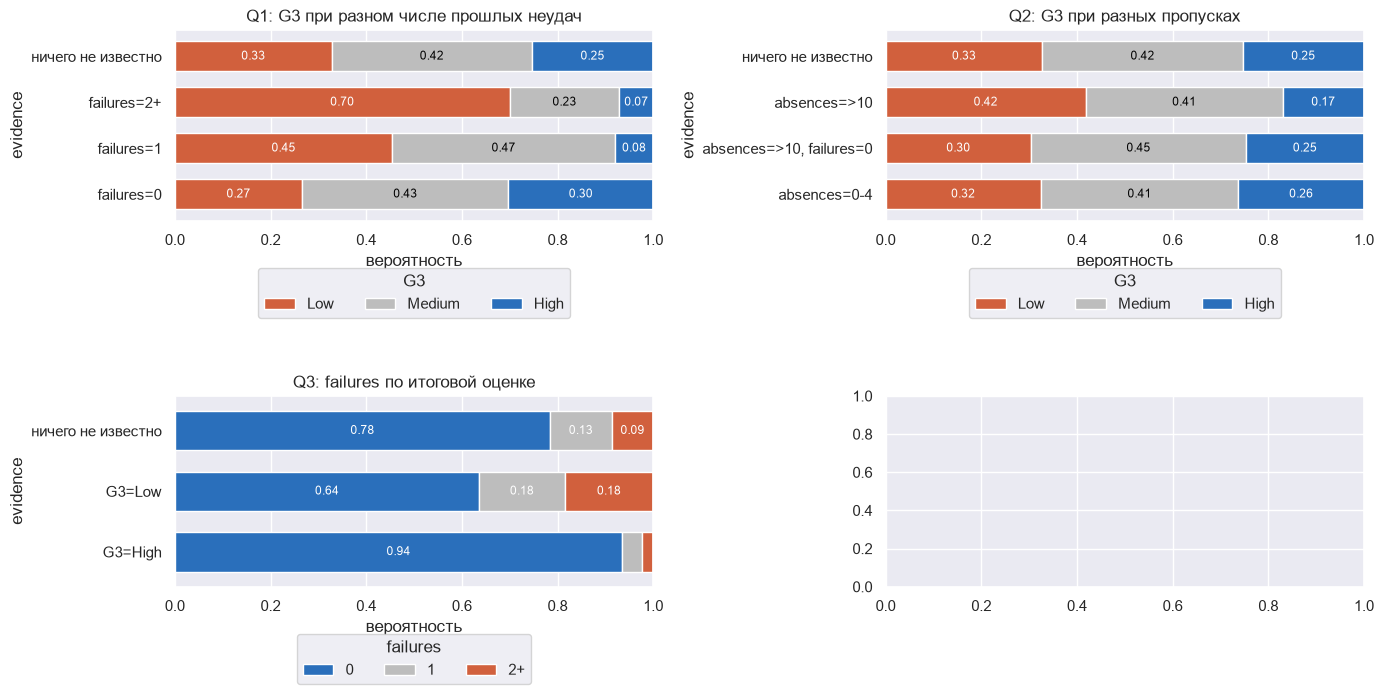

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
plot_steps(q1, "G3", "Q1: G3 при разном числе прошлых неудач", axes[0, 0])
plot_steps(q2, "G3", "Q2: G3 при разных пропусках", axes[0, 1])
plot_steps(q3a, "failures", "Q3: failures по итоговой оценке", axes[1, 0], colors={"0": "#2a6fbb", "1": "#bdbdbd", "2+": "#d1603d"})
plt.tight_layout(); plt.show()

## 7. Эксперимент с evidence

**Интересующая переменная — `G3`.** Последовательно добавляем сведения о других переменных. Цепочка **A** идёт от «фоновых» признаков к ближайшим; цепочка **B** показывает свойство *d-разделения*: когда известны родители `G3` (`G2` и `absences`), остальные переменные становятся для неё неинформативными.

,P(G3=Low),P(G3=Medium),P(G3=High),N в данных,частота Low,частота Medium,частота High
evidence,,,,,,,
0. ничего не известно,0.328,0.418,0.254,395,0.329,0.418,0.253
1. failures=2+,0.700,0.230,0.071,33,0.788,0.182,0.030
2. + studytime=1,0.790,0.190,0.020,15,0.800,0.200,0.000
3. + absences>10,0.910,0.071,0.019,3,1.000,0.000,0.000
4. + G1=Low,0.943,0.045,0.012,3,1.000,0.000,0.000
5. + G2=Low,0.955,0.039,0.006,3,1.000,0.000,0.000


,P(G3=Low),P(G3=Medium),P(G3=High),N в данных,частота Low,частота Medium,частота High
evidence,,,,,,,
0. G2=Medium,0.054,0.861,0.085,159,0.050,0.868,0.082
1. + absences>10,0.040,0.920,0.040,29,0.034,0.931,0.034
2. + G1=High,0.040,0.920,0.040,4,0.000,1.000,0.000
3. + failures=2+,0.040,0.920,0.040,1,0.000,1.000,0.000
4. + studytime=1,0.040,0.920,0.040,0,nan,nan,nan


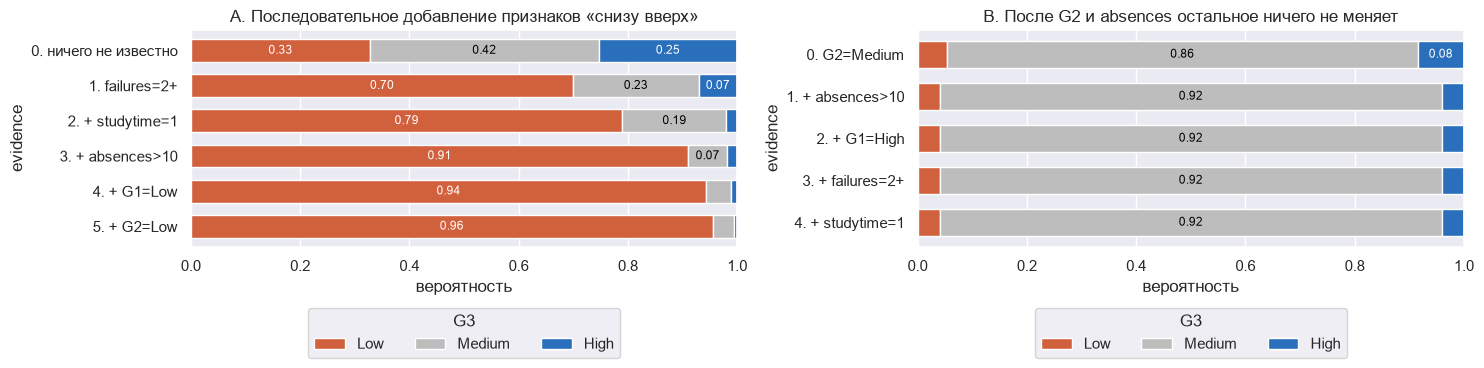

G3 ⫫ {G1, failures, studytime} | {G2, absences}: True


In [23]:
steps = [{}, {"failures": "2+"}, {"failures": "2+", "studytime": "1"}, {"failures": "2+", "studytime": "1", "absences": ">10"},
         {"failures": "2+", "studytime": "1", "absences": ">10", "G1": "Low"},
         {"failures": "2+", "studytime": "1", "absences": ">10", "G1": "Low", "G2": "Low"}]
names = ["0. ничего не известно", "1. failures=2+", "2. + studytime=1", "3. + absences>10", "4. + G1=Low", "5. + G2=Low"]
ev_a = evidence_table(model, "G3", steps, names)
display(pct(ev_a))

steps_b = [{"G2": "Medium"}, {"G2": "Medium", "absences": ">10"}, {"G2": "Medium", "absences": ">10", "G1": "High"},
           {"G2": "Medium", "absences": ">10", "G1": "High", "failures": "2+"},
           {"G2": "Medium", "absences": ">10", "G1": "High", "failures": "2+", "studytime": "1"}]
names_b = ["0. G2=Medium", "1. + absences>10", "2. + G1=High", "3. + failures=2+", "4. + studytime=1"]
ev_b = evidence_table(model, "G3", steps_b, names_b)
display(pct(ev_b))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_steps(ev_a, "G3", "A. Последовательное добавление признаков «снизу вверх»", axes[0])
plot_steps(ev_b, "G3", "B. После G2 и absences остальное ничего не меняет", axes[1])
plt.tight_layout(); plt.show()

print("G3 ⫫ {G1, failures, studytime} | {G2, absences}:",
      all(not model.is_dconnected("G3", v, observed=["G2", "absences"]) for v in ["G1", "failures", "studytime"]))

**Цепочка A (N: 33 → 15 → 3 → 3 → 3).**
- `failures=2+`: `P(G3=Low)` 0.33 → **0.70**: путь `failures → G1 → G2 → G3` и `failures → G2 → G3`, `failures → absences → G3`.
- `+ studytime=1`: → **0.79**. `studytime` влияет только через `G1`, эффект слабый, но совпадает по направлению.
- `+ absences>10`: → **0.91**. Самый большой шаг после первого: `absences` — **прямой родитель** `G3`, и при уже известных `failures` пропуски добавляют информацию именно по прямому ребру `absences → G3`.
- `+ G1=Low` и `+ G2=Low`: → 0.94 → **0.955**. Прирост небольшой: к этому моменту evidence и так почти однозначно указывает на `Low` (вероятность близка к потолку).
- Число подходящих под evidence студентов в данных падает до **3** — частота `Low` там 100%, а сеть выдаёт 0.91–0.96. Это нормально: три наблюдения — слишком мало, чтобы утверждать вероятность 1.0, а байесовская оценка + факторизация сглаживают результат. Это пример того, зачем нужна сеть: на подобных комбинациях прямая таблица бесполезна.

**Цепочка B.** При известных `G2 = Medium` распределение `G3` — (0.054, 0.861, 0.085). Добавление `absences>10` меняет его (→ 0.040, 0.920, 0.040): `absences` — родитель `G3`. После этого **ни `G1`, ни `failures`, ни `studytime` ничего не меняют** — вероятности остаются теми же до третьего знака (и это при том, что для последнего шага в данных нет ни одного подходящего студента: сеть всё равно отвечает). Причина — d-разделение: марковское одеяло `G3` = `{G2, absences}` (проверено в коде), и все пути от остальных узлов к `G3` проходят через эти два узла, которые теперь наблюдаются и блокируют их (цепи/развилки блокируются наблюдаемым узлом). Это ключевое свойство байесовской сети: **нужная информация о `G3` целиком содержится в её родителях**.

## 8. Анализ структуры

### 8.1. Удаление ребра

Проверим, как изменение структуры байесовской сети влияет на вероятностный вывод. Для этого удалим одно ребро `failures → G2`, заново оценим параметры сети и повторим запрос `P(G3 | failures = 2+)`.

Сравним результаты исходной сети и сети без выбранного ребра, чтобы оценить влияние структуры графа на полученные вероятности.

In [24]:
# Сравниваем исходную сеть и сеть без одного ребра
variants = {
    "Полная сеть": EDGES,
    "Без failures → G2": [
        e for e in EDGES if e != ("failures", "G2")
    ],
}

# Оцениваем параметры обеих сетей
models_v = {
    name: fit_bn(edges)
    for name, edges in variants.items()
}

# Один вероятностный запрос
evidence = {"failures": "2+"}

rows = []
for name, m in models_v.items():
    prob = ask(m, "G3", evidence)
    rows.append({
        "Структура": name,
        "P(G3=Low)": prob["Low"],
        "P(G3=Medium)": prob["Medium"],
        "P(G3=High)": prob["High"]
    })

display(
    pd.DataFrame(rows)
    .set_index("Структура")
    .round(3)
)

,P(G3=Low),P(G3=Medium),P(G3=High)
Структура,,,
Полная сеть,0.700,0.230,0.071
Без failures → G2,0.553,0.328,0.119


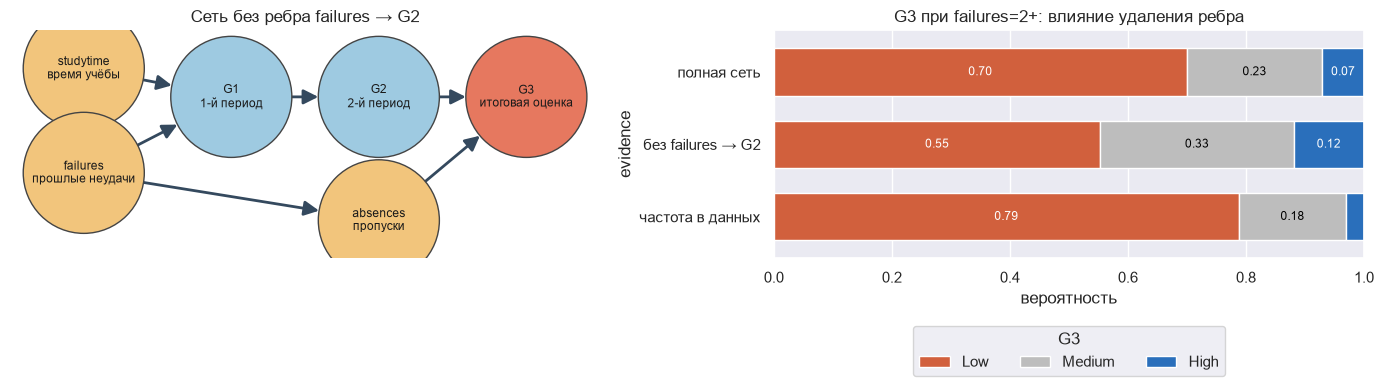

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
draw_dag(nx.DiGraph([e for e in EDGES if e != ("failures", "G2")]), "Сеть без ребра failures → G2", axes[0])
tbl = evidence_table(models_v["Без failures → G2"], "G3", [{"failures": "2+"}], ["без failures → G2"])
tbl = pd.concat([evidence_table(model, "G3", [{"failures": "2+"}], ["полная сеть"]), tbl,
                 evidence_table(model, "G3", [{"failures": "2+"}], ["частота в данных"]).assign(**{f"P(G3={s})": empirical("G3", {"failures": "2+"})[0][s] for s in GRADE})])
plot_steps(tbl, "G3", "G3 при failures=2+: влияние удаления ребра", axes[1])
plt.tight_layout(); plt.show()

**Результаты эксперимента.**

После удаления ребра `failures → G2` вероятность низкой итоговой оценки при наличии прошлых неудач уменьшается с 0.70 до 0.55.

Это показывает, что выбранное ребро существенно влияет на вероятностный вывод. Без него информация о прошлых неудачах передаётся к итоговой оценке преимущественно через другие узлы сети, поэтому получаемая вероятность меняется.

**Почему структура влияет на результат?**

Байесовская сеть задаёт зависимости и условные независимости между переменными. Удаление ребра `failures → G2` означает, что модель больше не учитывает непосредственную зависимость между прошлыми неудачами и оценкой второго периода.

В результате меняется распределение вероятностей последующих оценок.

**Вывод.** Даже одно ребро может заметно влиять на результаты вероятностного вывода. Поэтому при построении байесовской сети важно не только правильно определить набор переменных, но и обоснованно выбрать связи между ними.

## 9. Причинность

**Можно ли считать построенную сеть причинной моделью? — Нет, не целиком.** Стрелка в байесовской сети говорит лишь о том, какие условные распределения мы записали; сеть корректно описывает *наблюдательные* вероятности (что мы увидим, если узнаем X), но не обязана описывать, *что произойдёт, если мы вмешаемся* (do(X)).

**Где причинная интерпретация правдоподобна и на каком основании:**
- `failures → G1, G2`: основание — **временной порядок**: неудачи произошли до рассматриваемых оценок, поэтому обратного влияния быть не может. Но общие скрытые причины (способности, мотивация, семья) в модель не входят, так что даже здесь связь лишь *правдоподобно* причинная.
- `G1 → G2 → G3` — это скорее **предсказательная** цепочка: «лучшие результаты раньше → лучше позже»; общая причина (способности/подготовка) не моделируется, поэтому «вмешаться» в `G1` и ожидать эффекта на `G3` в том же размере нельзя.

**Где причинность сомнительна:**
- `absences → G3`: возможна обратная связь (низкие оценки → меньше желания ходить), скрытые общие причины (болезнь, мотивация) и артефакт `G3=0 ↔ absences=0` (выбывшие).
- `studytime → G1`: самооценка студента, общая причина — мотивация/способности.
- `failures → absences`: направление не выводится из данных (марковская эквивалентность, раздел 8.2).

**Иллюстрация разницы «наблюдение ↔ вмешательство» (слайд «Наблюдение и вмешательство»).** Сравним `P(G3 | absences)` (увидели) и `P(G3 | do(absences))` (заставили студента пропускать/не пропускать; в сети удаляется входящее ребро `failures → absences`):

## 10. Итоги

**Что удалось узнать.**
- Итоговая оценка почти полностью определяется оценкой второго периода: при известных `G2` и `absences` остальные признаки не добавляют информации (d-разделение подтверждено и в графе, и на данных — тесты `failures ⫫ G3 | G2, absences`, p = 0.85, и `studytime ⫫ G3 | …`, p = 0.75).
- Наиболее информативный «внешний» фактор — прошлые неудачи: при `failures = 2+` вероятность низкой итоговой оценки вырастает с 0.33 до 0.70 (по данным 0.79), а высокой падает с 0.25 до 0.07.
- Время учёбы — очень слабый предиктор: информация о нём затухает по цепочке `studytime → G1 → G2 → G3`; итоговая оценка почти ничего не говорит о времени учёбы.
- Много пропусков (>10) повышают вероятность `Low` с 0.33 до 0.42, но значительная часть этой связи объясняется студентами с прошлыми неудачами; при `failures=0` эффект почти исчезает.

**Наиболее интересные зависимости.**
- `failures → absences → G3` вместе с `failures → G1 → G2 → G3`: конфаундер, который разделяет «наблюдаемый» и «вмешательственный» эффект пропусков (0.42 vs 0.37).
- «Странная» немонотонность `P(G3 | absences)`, которая оказалась артефактом данных — все 38 студентов с `G3=0` имеют `absences=0`.
- Недостаток прямого ребра `failures → G2`, который выяснился только при проверке модели против данных (0.70 против 0.79).

**Как evidence влияет на вероятности.** Evidence переносится по графу — и вдоль, и против стрелок (Q3). Добавление родителей целевой переменной (`G2`, `absences`) меняет её распределение сильнее всего, а после их наблюдения остальные узлы перестают влиять (цепочка B в разделе 7). По мере добавления признаков в цепочке A вероятность `Low` монотонно растёт 0.33 → 0.70 → 0.79 → 0.91 → 0.94 → 0.96, при этом прирост сначала большой (косвенные признаки), потом малый (всё уже ясно).

**Зависимость от структуры.** Существенная. Удаление `failures → G2` сдвигает ответ на 15 п.п. при том, что score практически не различает структуры; удаление `absences → G3` меняет только запросы про пропуски; направление `failures ↔ absences` определить по данным нельзя (марковская эквивалентность), а score-based поиск (BIC) выдаёт очень разреженный граф, лишённый половины интересующих нас переменных.

**Ограничения модели.**
- *Малый объём данных:* 395 студентов на 71 параметр; многие строки CPT основаны на единицах наблюдений, и ответы для них определяются сглаживанием (ESS) — для редких комбинаций (`failures=2+`, `studytime=4`) модель ненадёжна.
- *Грубая дискретизация:* границы 9/10 и 13/14 разделяют почти одинаковых студентов (пример `G2=10 → G3=9`) и «склеивают» разных внутри групп; зависимость от `failures` для `G2` частично объясняется именно этим.
- *Артефакт данных:* 38 студентов с `G3=0` и `absences=0`.
- *Ненаблюдаемые факторы:* способности, мотивация, семья, школа — не в модели; они создают скрытые зависимости и ограничивают причинную интерпретацию.
- *Допущения графа:* `studytime ⫫ failures`, отсутствие прямых `studytime → G2`, `G1 → G3` — по тестам нарушаются слабо, но нарушаются.
- *Данные одной выборки:* две школы Португалии, предмет «математика»; обобщение на другие группы не обосновано.